# Lab 1 — Intro to Behavioral TV Data
Name: Artem Khailo | Group: KM-42

## Setup

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")  # Colab and Kaggle
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


## Task 1.1 — Panel and universe

In [2]:
kind= daily_weights["resp_type"].map({"H": "households", "R": "persons", "L": "persons"})
by_day = daily_weights.groupby([kind, "broadcast_date"])["weight"].agg(in_tab="size", universe="sum")
avg_day =by_day.groupby(level=0).mean()
panel = daily_weights.groupby(kind)["respondent_id"].nunique()
missing= viewer_attributes.loc[~viewer_attributes["respondent_id"].isin(daily_weights["respondent_id"]),
                                "respondent_id"].unique()

print("Telecasts:", programs["telecast_id"].nunique())
print("Programs:", programs["program_name"].nunique())
print("Networks:", programs["network_code"].nunique())
print("Households in panel:", panel["households"])
print("Persons in panel:", panel["persons"])
print("Households in-tab, average day:", round(avg_day.loc["households", "in_tab"], 1))
print("Persons in-tab, average day:", round(avg_day.loc["persons", "in_tab"], 1))
print("US TV households represented, average day (M):", f'{avg_day.loc["households", "universe"] / 1e6:.2f}')
print("US persons represented, average day (M):", f'{avg_day.loc["persons", "universe"] / 1e6:.2f}')
print("Only in viewer_attributes:", len(missing), "ids from", len(set(missing // 100)), "households,",
      viewings["respondent_id"].isin(missing).sum(), "viewing rows")

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878.5
Persons in-tab, average day: 9268.7
US TV households represented, average day (M): 125.80
US persons represented, average day (M): 317.28
Only in viewer_attributes: 8 ids from 2 households, 0 viewing rows


**Answer:** `programs` holds 5,841 telecasts of 246 distinct programs (counted by title, so a title on two networks counts once) on 10 networks.
In October 4,254 households and 10,210 persons (R and L) were in-tab at least once, but because households join and leave the panel during the month and some days are missed, an average day has only 3,878.5 households and 9,268.7 persons in-tab.
`viewer_attributes` lists 8 more records: 2 households and their 6 members, who are recruited and have demographics but were never in-tab in October (no daily weight, no viewing), e.g. their meter was not yet or no longer reporting.
Every day the weights project the in-tab sample to the whole universe: 125.80 M US TV households and 317.28 M persons 2+.

## Task 1.2 — Average audience by hour of day

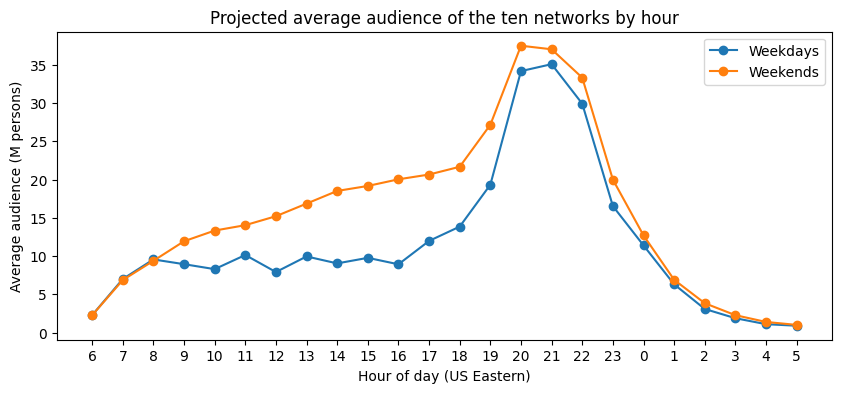

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [3]:
pv =viewings[viewings["resp_type"].isin(["R", "L"])]

first_hour=pv["start_ts"].dt.floor("h")
pieces = []
k=0
while True:
    h_start = first_hour + pd.Timedelta(hours=k)
    h_end = h_start + pd.Timedelta(hours=1)
    minutes = (pv["end_ts"].clip(upper=h_end) - pv["start_ts"].clip(lower=h_start)).dt.total_seconds() / 60
    inside = minutes > 0
    if not inside.any():
        break
    pieces.append(pd.DataFrame({"hour_ts": h_start[inside], "w_min": minutes[inside] * pv["weight"][inside]}))
    k += 1
hourly = pd.concat(pieces)

hourly["weekend"] = (hourly["hour_ts"] - pd.Timedelta(hours=6)).dt.dayofweek >= 5
hourly["hour"] = hourly["hour_ts"].dt.hour

days = pd.to_datetime(pd.Series(daily_weights["broadcast_date"].unique()))
n_days = {False: (days.dt.dayofweek < 5).sum(), True: (days.dt.dayofweek >= 5).sum()}

aa= hourly.groupby(["weekend", "hour"])["w_min"].sum().unstack(0)
aa = aa / 60 / pd.Series(n_days) / 1e6
aa.columns =["Weekdays", "Weekends"]
order = list(range(6, 24)) + list(range(0, 6))
aa= aa.loc[order]

ax = aa.plot(marker="o", figsize=(10, 4), use_index=False)
ax.set_xticks(range(24))
ax.set_xticklabels(order)
ax.set_xlabel("Hour of day (US Eastern)")
ax.set_ylabel("Average audience (M persons)")
ax.set_title("Projected average audience of the ten networks by hour")
plt.show()

print("Peak hour, weekdays:", aa["Weekdays"].idxmax())
print("Peak hour, weekends:", aa["Weekends"].idxmax())

**Answer:** Prime time is the peak on both: 21:00 on weekdays and 20:00 on weekends, so the weekend peak comes an hour earlier and is slightly higher (about 37.5 M vs 35 M). The real difference is the daytime: on weekdays the curve stays low and flat until late afternoon and then rises sharply between 19:00 and 20:00, while on weekends it climbs steadily from the morning, so in the early afternoon about twice as many people watch (at 14:00 roughly 18 M vs 9 M). Before 9:00 and after midnight weekdays and weekends look almost the same.

## Task 1.3 — Session length

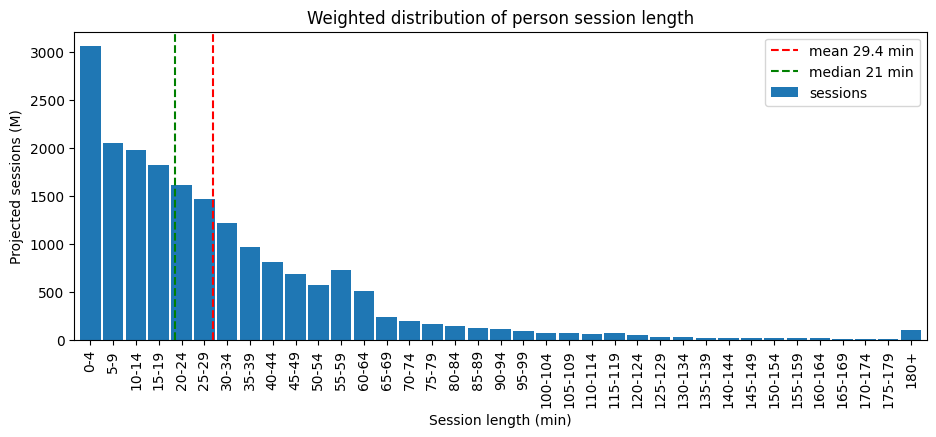

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21


In [4]:
length =(pv["end_ts"] - pv["start_ts"]).dt.total_seconds() / 60
proj =pv["weight"].groupby(length).sum()
share =proj / proj.sum()

mean_len= (share * share.index).sum()
median_len= share.cumsum().ge(0.5).idxmax()
bins =(proj.index.to_series() // 5 * 5).clip(upper=180)
dist = proj.groupby(bins).sum() / 1e6
ax =dist.plot.bar(figsize=(11, 4), width=0.9, label="sessions")
ax.set_xticklabels([f"{b:.0f}+" if b == 180 else f"{b:.0f}-{b + 4:.0f}" for b in dist.index], rotation=90)
ax.axvline(mean_len / 5 - 0.5, color="red", ls="--", label=f"mean {mean_len:.1f} min")
ax.axvline(median_len / 5 - 0.5, color="green", ls="--", label=f"median {median_len:.0f} min")
ax.set_xlabel("Session length (min)")
ax.set_ylabel("Projected sessions (M)")
ax.set_title("Weighted distribution of person session length")
ax.legend()
plt.show()

print("Session length, weighted mean (min):", round(mean_len, 1))
print("Session length, weighted median (min):", round(median_len))

**Answer:** The weighted mean is 29.4 minutes and the weighted median is 21 minutes. Half of all projected sessions are shorter than 21 minutes, and the tallest bar is the shortest one (under 5 minutes). The mean is higher because it is total viewing time divided by the number of sessions, so the long right tail of the histogram (sessions of an hour or more, up to the 180+ bar) adds a lot of minutes while adding only a few sessions. For a client deck I would use the median: it shows what a typical session looks like and is not moved by a small number of very long ones.

## Task 2 — Program reach curve

                HH rating (%)  P2+ rating (%)  Audience (M)
broadcast_date                                             
2024-10-01                3.5             1.7          5.28
2024-10-02                3.1             1.5          4.68
2024-10-03                3.0             1.5          4.68
2024-10-04                3.0             1.5          4.81
2024-10-07                3.1             1.5          4.83
2024-10-08                3.2             1.6          4.97
2024-10-09                3.0             1.5          4.70
2024-10-10                3.4             1.6          5.13
2024-10-11                3.1             1.5          4.69
2024-10-14                2.9             1.4          4.59
2024-10-15                3.1             1.5          4.82
2024-10-16                3.0             1.5          4.62
2024-10-17                3.4             1.7          5.30
2024-10-18                2.7             1.3          4.23
2024-10-21                3.1           

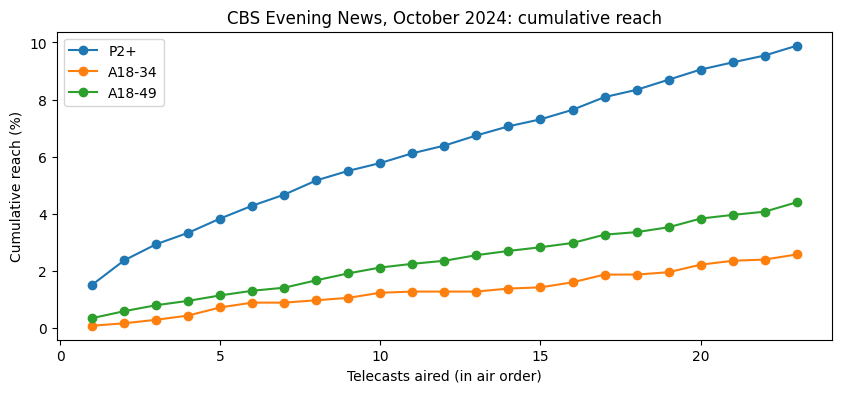

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [7]:
def telecast_viewers(telecasts):
    found= []
    for t in telecasts.itertuples():
        s =viewings[(viewings["network_code"] == t.network_code) & (viewings["resp_type"] != "S") & (viewings["start_ts"] < t.end_ts) & (viewings["end_ts"] > t.start_ts)]
        overlap = (s["end_ts"].clip(upper=t.end_ts) - s["start_ts"].clip(lower=t.start_ts)).dt.total_seconds() / 60
        mins = overlap.groupby([s["respondent_id"], s["resp_type"]]).sum()
        watched = mins[mins >= 1].reset_index()[["respondent_id", "resp_type"]]
        watched["telecast_id"] = t.telecast_id
        watched["broadcast_date"] = t.broadcast_date
        found.append(watched)
    return pd.concat(found, ignore_index=True)

news= programs[programs["program_name"] == "CBS Evening News"].sort_values("start_ts")
assert news["broadcast_date"].is_unique
seen= telecast_viewers(news).merge(daily_weights, on=["respondent_id", "resp_type", "broadcast_date"])
seen["kind"] =seen["resp_type"].map({"H": "households", "R": "persons", "L": "persons"})

watch =seen.groupby(["kind", "broadcast_date"])["weight"].sum()
universe =by_day["universe"].rename_axis(["kind", "broadcast_date"])
rating =(watch / universe * 100).dropna().unstack(0)
table =pd.DataFrame({"HH rating (%)": rating["households"],
                      "P2+ rating (%)": rating["persons"],
                      "Audience (M)": watch["persons"] / 1e6})
print(table.round({"HH rating (%)": 1, "P2+ rating (%)": 1, "Audience (M)": 2}).to_string())

persons =daily_weights[daily_weights["resp_type"].isin(["R", "L"])].groupby("respondent_id")["weight"].mean()
age= viewer_attributes[viewer_attributes["attr_id"] == 300].set_index("respondent_id")["value"]
persons=pd.DataFrame({"w": persons, "age": age.reindex(persons.index)})
targets={"P2+": persons, "A18-34": persons[persons["age"].between(18, 34)], "A18-49": persons[persons["age"].between(18, 49)]}
order = {tid: i for i, tid in enumerate(news["telecast_id"], start=1)}
first_seen = (seen[seen["kind"] == "persons"].assign(n=lambda d: d["telecast_id"].map(order)).groupby("respondent_id")["n"].min())
reach = pd.DataFrame(index=range(1, len(news) + 1))
for name, people in targets.items():
    new_w= people["w"].groupby(first_seen.reindex(people.index)).sum()
    reach[name] = new_w.reindex(reach.index, fill_value=0).cumsum() / people["w"].sum() * 100

ax = reach.plot(marker="o", figsize=(10, 4))
ax.set_xlabel("Telecasts aired (in air order)")
ax.set_ylabel("Cumulative reach (%)")
ax.set_title("CBS Evening News, October 2024: cumulative reach")
plt.show()

print("Telecasts of the program:", len(news))
print("Average household rating (%):", round(table["HH rating (%)"].mean(), 1))
print("Average P2+ rating (%):", round(table["P2+ rating (%)"].mean(), 1))
print("Average projected audience (M):", f'{table["Audience (M)"].mean():.2f}')
print("Final reach P2+ (%):", round(reach["P2+"].iloc[-1], 1))
print("Final reach A18-34 (%):", round(reach["A18-34"].iloc[-1], 1))
print("Final reach A18-49 (%):", round(reach["A18-49"].iloc[-1], 1))

**Answer:** Each telecast has a rating of about 3.2% of households and 1.6% of persons (4.93 M people on average), and these numbers barely move from day to day. Cumulative reach is a different measure: the share of people who saw at least one of the telecasts so far. On every new day part of the audience are people who already watched earlier in the month (duplication), and only the rest are new, so reach rises from 1.5% to 9.9% after 23 telecasts while the ratings stay flat; adding up the ratings (about 37%) would count the same loyal viewers many times. P2+ is the best-reached of the three audiences: 9.9% against 4.4% for A18–49 and only 2.6% for A18–34, so the younger the target, the lower the reach. That fits the usual picture of network evening news: a program for an older audience that watches the news at dinner time, while younger adults get their news online.

## Task 3 — Program frequency

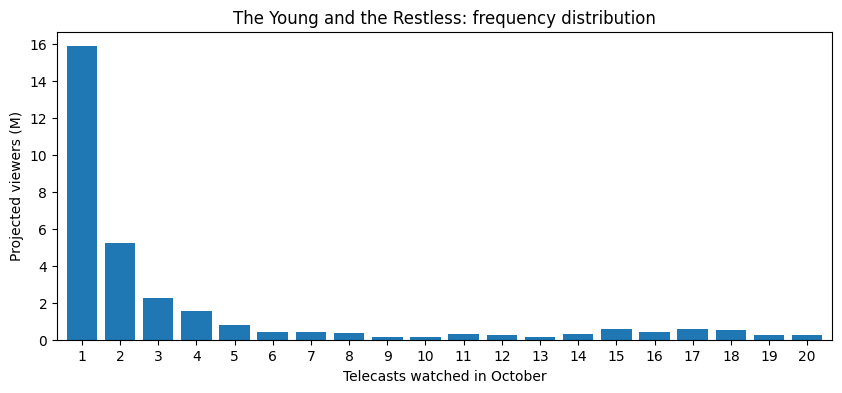

Projected viewers (M): 30.80
Average frequency (weighted): 3.6
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704


In [8]:
yr= programs[programs["program_name"] == "The Young and the Restless"]
yr_seen= telecast_viewers(yr)
yr_seen = yr_seen[yr_seen["resp_type"].isin(["R", "L"])]

fr =yr_seen.groupby("respondent_id")["telecast_id"].nunique().rename("freq").to_frame()
fr["w"] = persons["w"].reindex(fr.index)
by_freq=fr.groupby("freq")["w"].sum()
cum_share = by_freq.cumsum() / by_freq.sum()

def freq_quantile(q):
    return cum_share[cum_share >= q].index[0]

viewers= by_freq.sum()
avg_freq= (by_freq * by_freq.index).sum() / viewers
p80= freq_quantile(0.8)
views= by_freq * by_freq.index
loyal_share= views[views.index >= p80].sum() / views.sum()
ax= (by_freq / 1e6).plot.bar(figsize=(10, 4), width=0.8, rot=0)
ax.set_xlabel("Telecasts watched in October")
ax.set_ylabel("Projected viewers (M)")
ax.set_title("The Young and the Restless: frequency distribution")
plt.show()

print("Projected viewers (M):", f"{viewers / 1e6:.2f}")
print("Average frequency (weighted):", round(avg_freq, 1))
print("Median frequency (weighted):", freq_quantile(0.5))
print("Share of views from the most loyal viewers:", f"{loyal_share:.3f}")

**Answer:** The soap reached 30.80 M people in October. The weighted average frequency is 3.6 telecasts, but the weighted median is only 1, and the histogram shows why: the biggest bar by far is people who saw a single episode, the bars fall quickly after 2–3 episodes, and then there is a second small bump of daily fans at about 15–18 episodes. The most loyal viewers (at or above the weighted 80th percentile of frequency) produce 70.4% of all projected views. So the views are very concentrated: a minority of heavy viewers watches most of the episodes and pulls the average up, while the typical viewer tuned in only once. One average number hides this, so it is not a fair summary here; you need the whole distribution, or at least the median next to the mean.

## Task 4 — Networks by age and gender

In [10]:
va=viewer_attributes.merge(attributes, on="attr_id", how="left")
sex= va.loc[va["attr_group"] == "Sex"].set_index("respondent_id")["attr_name"].str[0].replace({"F": "W"})
mm = pd.DataFrame({"network": pv["network_code"], "minutes": length,"proj_min": length * pv["weight"],"sex": pv["respondent_id"].map(sex),
                   "band": pd.cut(pv["respondent_id"].map(age), bins=[17, 34, 54, 200], labels=["18-34", "35-54", "55+"]),
})
mm["audience"] = mm["sex"] + mm["band"].astype("string")
by_aud = mm.pivot_table(index="network", columns="audience", values="proj_min", aggfunc="sum") / 1e6
for aud in ["M18-34", "W18-34", "M35-54", "W35-54", "M55+", "W55+"]:
    print(f"Top 5 networks, {aud} (projected minutes, M):")
    print(by_aud[aud].nlargest(5).round(2).to_string(), "\n")

young= mm["band"] == "18-34"
total =mm.groupby("network")[["proj_min", "minutes"]].sum()
from_young =mm[young].groupby("network")[["proj_min", "minutes"]].sum()
share =(from_young / total).rename(columns={"proj_min": "weighted", "minutes": "raw"})
share = share.sort_values("weighted", ascending=False)
print("Share of minutes from 18-34 viewers:")
print(share.round(3).to_string(), "\n")

print("Youngest network:", share["weighted"].idxmax())
print("Oldest network:", share["weighted"].idxmin())

Top 5 networks, M18-34 (projected minutes, M):
network
FOX    4386.65
NBC    3910.39
CBS    3044.35
ABC    3010.78
FX     1473.96 

Top 5 networks, W18-34 (projected minutes, M):
network
FOX    4574.44
NBC    4527.59
ABC    3504.86
CBS    2811.22
FX     1383.47 

Top 5 networks, M35-54 (projected minutes, M):
network
FOX    12804.67
NBC    10986.68
ABC     9037.00
CBS     8134.07
FX      2370.80 

Top 5 networks, W35-54 (projected minutes, M):
network
NBC     11639.10
FOX     11161.39
ABC      9438.56
CBS      8162.80
HGTV     3051.81 

Top 5 networks, M55+ (projected minutes, M):
network
CBS    38274.03
NBC    34267.41
FOX    30878.51
ABC    30793.34
FNC    27903.71 

Top 5 networks, W55+ (projected minutes, M):
network
CBS    47120.32
NBC    41391.87
ABC    38840.01
FOX    36914.72
FNC    31450.73 

Share of minutes from 18-34 viewers:
         weighted    raw
network                 
FX          0.266  0.232
BRAVO       0.148  0.127
FOX         0.082  0.075
FOOD        0.078  0.071


**Answer:** The big broadcast networks dominate all six lists simply because they carry most of the viewing: FOX and NBC lead the 18–34 and 35–54 audiences (FX and HGTV are the only cable networks in those top 5), and CBS leads both 55+ audiences, where Fox News also enters the top 5. Measured by the share of its minutes that come from 18–34 viewers, FX is the youngest network (0.266) and Fox News the oldest (0.018). The raw panel shares are smaller for every network, for example FX 0.232 and Bravo 0.127 instead of 0.148. Since raw and weighted shares use the same viewing minutes, the gap can only come from the weights: young adults in the panel get higher weights than average, which means there are fewer of them in the panel than in the US population, so each one has to stand for more people. A client who got raw panel numbers would see a sample, not the country: young audiences would look smaller than they are, every network's age profile would be shifted towards older viewers, and ratings and prices for young-adult targets would be wrong.

**Bonus answer:** Fox News has a very large total audience, so even its small young share is real volume, and that volume is priced on its older core, which makes the young adults it does deliver cheap. I would offer a young-adult advertiser a low-cost add-on built around *Gutfeld!* at 22:00, the channel's late-night comedy show and the most natural place on it for younger viewers, to pick up young people who are not reached by FX or Bravo.